<a href="https://colab.research.google.com/github/ImanMahato05/Project-2/blob/main/Stage_1_3_marginal_effect_curve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


####Preliminary independent calculation and plotting (GPCP and GPCC)

In [2]:
from pathlib import Path

STAGE1 = Path(
    "/content/drive/MyDrive/ecohydro_project/Project 2/Stage 1"
)

REGRESSION_DIR = (
    STAGE1 / "Benchmark_Reproduction" / "GPCC_GPCP_Results"
)

GITHUB_RESULTS_DIR = (
    STAGE1 / "GitHub_Repository" / "reg_results"
)

MARGINAL_DIR = (
    STAGE1 / "Benchmark_Reproduction" / "Marginal_Effect_Curve"
)

MARGINAL_DIR.mkdir(parents=True, exist_ok=True)

print("Regression folder exists:", REGRESSION_DIR.exists())
print("GitHub reference folder exists:", GITHUB_RESULTS_DIR.exists())
print("Marginal-effect folder exists:", MARGINAL_DIR.exists())
print("Output folder:", MARGINAL_DIR)

Regression folder exists: True
GitHub reference folder exists: True
Marginal-effect folder exists: True
Output folder: /content/drive/MyDrive/ecohydro_project/Project 2/Stage 1/Benchmark_Reproduction/Marginal_Effect_Curve


In [3]:
import pandas as pd

gpcp_file = REGRESSION_DIR / "GPCP_regression_results.csv"
gpcc_file = REGRESSION_DIR / "GPCC_regression_results.csv"
cpc_file = GITHUB_RESULTS_DIR / "CPC_regression_results.csv"

print("GPCP exists:", gpcp_file.exists())
print("GPCC exists:", gpcc_file.exists())
print("CPC reference exists:", cpc_file.exists())

gpcp = pd.read_csv(gpcp_file)
gpcc = pd.read_csv(gpcc_file)

print("\nGPCP regression results:")
display(gpcp.T)

print("\nGPCC regression results:")
display(gpcc.T)

GPCP exists: True
GPCC exists: True
CPC reference exists: True

GPCP regression results:


,0
Unnamed: 0,1.000000e+00
coef_P,7.902013e-03
se_P,9.786376e-04
pval_P,5.192782e-15
coef_T,-1.527846e-01
se_T,6.936537e-02
pval_T,2.808269e-02
coef_Gp,-1.937996e+01
se_Gp,5.242270e+00
pval_Gp,2.426725e-04



GPCC regression results:


,0
Unnamed: 0,1.000000e+00
coef_P,5.074002e-03
se_P,6.303518e-04
pval_P,6.415536e-15
coef_T,-1.197601e-01
se_T,8.664822e-02
pval_T,1.675617e-01
coef_Gp,-1.883289e+01
se_Gp,3.138840e+00
pval_Gp,3.855030e-09


In [4]:
import numpy as np
import pandas as pd

def calculate_marginal_effect(regression_file, product_name):

    # Load the regression result
    results = pd.read_csv(regression_file)

    if len(results) != 1:
        raise ValueError(
            f"{product_name}: Expected one row in regression result file."
        )

    row = results.iloc[0]

    # Extract regression coefficients
    gamma = float(row["coef_Gp"])
    chi = float(row["coef_GpP"])

    # Extract standard errors
    se_gamma = float(row["se_Gp"])
    se_chi = float(row["se_GpP"])

    # Extract covariance
    covariance = float(row["vcov"])

    # Mean precipitation values: 0 to 3600 mm
    mean_precipitation = np.arange(0, 3601, 10)

    # Calculate marginal effect
    marginal_effect = gamma + chi * mean_precipitation

    # Calculate variance of marginal effect
    variance = (
        se_gamma**2
        + mean_precipitation**2 * se_chi**2
        + 2 * mean_precipitation * covariance
    )

    # Check that the variance is valid
    if np.any(variance < -1e-10):
        raise ValueError(
            f"{product_name}: Negative variance encountered."
        )

    # Avoid tiny negative values caused by floating-point rounding
    variance = np.maximum(variance, 0)

    # Calculate standard error
    marginal_se = np.sqrt(variance)

    # Calculate ±2 standard-error boundaries
    upper = marginal_effect + 2 * marginal_se
    lower = marginal_effect - 2 * marginal_se

    # Store all calculated values in a DataFrame
    curve_data = pd.DataFrame({
        "mean_precipitation_mm": mean_precipitation,
        "marginal_effect_mm_per_0.1_GP": marginal_effect,
        "standard_error": marginal_se,
        "upper_2SE": upper,
        "lower_2SE": lower
    })

    curve_data["product"] = product_name

    return curve_data


# Calculate GPCP marginal effects
gpcp_curve = calculate_marginal_effect(
    gpcp_file, "GPCP"
)

# Calculate GPCC marginal effects
gpcc_curve = calculate_marginal_effect(
    gpcc_file, "GPCC"
)

print("GPCP marginal-effect calculations:")
display(gpcp_curve.head())

print("GPCC marginal-effect calculations:")
display(gpcc_curve.head())

GPCP marginal-effect calculations:


,mean_precipitation_mm,marginal_effect_mm_per_0.1_GP,standard_error,upper_2SE,lower_2SE,product
0,0,-19.379957,5.242270,-8.895418,-29.864496,GPCP
1,10,-19.571874,5.182299,-9.207277,-29.936472,GPCP
2,20,-19.763792,5.122959,-9.517874,-30.009709,GPCP
3,30,-19.955709,5.064272,-9.827165,-30.084252,GPCP
4,40,-20.147626,5.006260,-10.135105,-30.160147,GPCP


GPCC marginal-effect calculations:


,mean_precipitation_mm,marginal_effect_mm_per_0.1_GP,standard_error,upper_2SE,lower_2SE,product
0,0,-18.832890,3.138840,-12.555211,-25.110569,GPCC
1,10,-18.905656,3.119375,-12.666906,-25.144406,GPCC
2,20,-18.978422,3.100094,-12.778233,-25.178610,GPCC
3,30,-19.051188,3.081001,-12.889185,-25.213190,GPCC
4,40,-19.123954,3.062099,-12.999755,-25.248152,GPCC


In [5]:
def check_at_1000(curve_data, product_name):

    result = curve_data.loc[
        curve_data["mean_precipitation_mm"] == 1000
    ].iloc[0]

    effect = result["marginal_effect_mm_per_0.1_GP"]
    se = result["standard_error"]
    half_width = 2 * se

    print(f"\n{product_name}")
    print("-" * 40)
    print(f"Marginal effect: {effect:.3f} mm")
    print(f"Standard error:  {se:.3f} mm")
    print(f"±2 SE half-width: {half_width:.3f} mm")
    print(f"Lower boundary: {result['lower_2SE']:.3f} mm")
    print(f"Upper boundary: {result['upper_2SE']:.3f} mm")


check_at_1000(gpcp_curve, "GPCP")
check_at_1000(gpcc_curve, "GPCC")


GPCP
----------------------------------------
Marginal effect: -38.572 mm
Standard error:  5.706 mm
±2 SE half-width: 11.411 mm
Lower boundary: -49.983 mm
Upper boundary: -27.160 mm

GPCC
----------------------------------------
Marginal effect: -26.109 mm
Standard error:  2.659 mm
±2 SE half-width: 5.318 mm
Lower boundary: -31.428 mm
Upper boundary: -20.791 mm


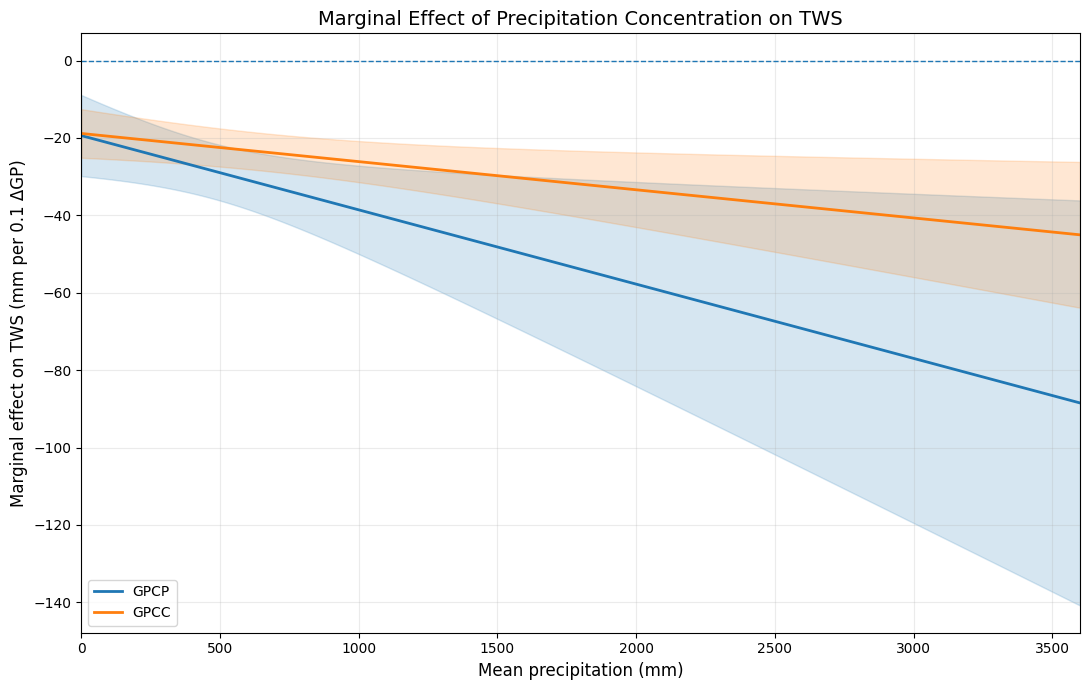

Figure saved: /content/drive/MyDrive/ecohydro_project/Project 2/Stage 1/Benchmark_Reproduction/Marginal_Effect_Curve/GPCP_GPCC_Marginal_Effect_Curve.png


In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

# GPCP
line_gpcp, = plt.plot(
    gpcp_curve["mean_precipitation_mm"],
    gpcp_curve["marginal_effect_mm_per_0.1_GP"],
    label="GPCP",
    linewidth=2
)

plt.fill_between(
    gpcp_curve["mean_precipitation_mm"],
    gpcp_curve["lower_2SE"],
    gpcp_curve["upper_2SE"],
    color=line_gpcp.get_color(),
    alpha=0.18
)

# GPCC
line_gpcc, = plt.plot(
    gpcc_curve["mean_precipitation_mm"],
    gpcc_curve["marginal_effect_mm_per_0.1_GP"],
    label="GPCC",
    linewidth=2
)

plt.fill_between(
    gpcc_curve["mean_precipitation_mm"],
    gpcc_curve["lower_2SE"],
    gpcc_curve["upper_2SE"],
    color=line_gpcc.get_color(),
    alpha=0.18
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Mean precipitation (mm)", fontsize=12)
plt.ylabel(
    "Marginal effect on TWS (mm per 0.1 ΔGP)",
    fontsize=12
)
plt.title(
    "Marginal Effect of Precipitation Concentration on TWS",
    fontsize=14
)

plt.xlim(0, 3600)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

figure_path = (
    MARGINAL_DIR / "GPCP_GPCC_Marginal_Effect_Curve.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

In [7]:
# Combine both products into one table
all_curves = pd.concat(
    [gpcp_curve, gpcc_curve],
    ignore_index=True
)

# Save the combined calculation table
curve_csv_path = (
    MARGINAL_DIR / "GPCP_GPCC_Marginal_Effect_Calculations.csv"
)

all_curves.to_csv(curve_csv_path, index=False)

print("Calculation table saved:", curve_csv_path)
print("Total calculation rows:", len(all_curves))

Calculation table saved: /content/drive/MyDrive/ecohydro_project/Project 2/Stage 1/Benchmark_Reproduction/Marginal_Effect_Curve/GPCP_GPCC_Marginal_Effect_Calculations.csv
Total calculation rows: 722


####Final reproduction using the authors' calculation and plotting approach --------------------------------------


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CPC: authors' original regression results
cpc_file = GITHUB_RESULTS_DIR / "CPC_regression_results.csv"

# GPCP and GPCC: our reproduced regression results
gpcp_file = REGRESSION_DIR / "GPCP_regression_results.csv"
gpcc_file = REGRESSION_DIR / "GPCC_regression_results.csv"

cpc_results = pd.read_csv(cpc_file)
gpcp_results = pd.read_csv(gpcp_file)
gpcc_results = pd.read_csv(gpcc_file)

print("CPC results loaded:", cpc_file.exists())
print("GPCP results loaded:", gpcp_file.exists())
print("GPCC results loaded:", gpcc_file.exists())

display(cpc_results)
display(gpcp_results)
display(gpcc_results)

CPC results loaded: True
GPCP results loaded: True
GPCC results loaded: True


,Unnamed: 0,coef_P,se_P,pval_P,coef_T,se_T,pval_T,coef_Gp,se_Gp,pval_Gp,coef_GpP,se_GpP,pval_GpP,R2,model_pval,vcov
0,1,0.0033,0.000721,0.000006,-0.159641,0.074344,0.032239,-15.790201,4.462709,0.00044,-0.006864,0.003505,0.05074,0.01115,2.396633e-27,-0.011419


,Unnamed: 0,coef_P,se_P,pval_P,coef_T,se_T,pval_T,coef_Gp,se_Gp,pval_Gp,coef_GpP,se_GpP,pval_GpP,R2,model_pval,vcov
0,1,0.007902,0.000979,5.192782e-15,-0.152785,0.069365,0.028083,-19.379957,5.24227,0.000243,-0.019192,0.008263,0.020601,0.08415,5.519801e-75,-0.0316


,Unnamed: 0,coef_P,se_P,pval_P,coef_T,se_T,pval_T,coef_Gp,se_Gp,pval_Gp,coef_GpP,se_GpP,pval_GpP,R2,model_pval,vcov
0,1,0.005074,0.00063,6.415536e-15,-0.11976,0.086648,0.167562,-18.83289,3.13884,3.855030e-09,-0.007277,0.003081,0.018593,0.044011,2.607926e-45,-0.006138


In [17]:
# AUTHORS' ORIGINAL MARGINAL-EFFECT CALCULATION

# Unit conversion:
# GP change = 0.1
# LWE is in cm; convert to mm using 10
cm_to_mm = 10

scale = 0.1
scale = scale * cm_to_mm

n_se = 2

# Mean precipitation range
bmin = 0
bmax = 3600
freq = 100

x = np.arange(bmin, bmax, freq)



# CPC

gamma_abs = cpc_results["coef_Gp"][0]
chi_abs = cpc_results["coef_GpP"][0]

gamma_se = cpc_results["se_Gp"][0]
chi_se = cpc_results["se_GpP"][0]

cov_gamma_chi = cpc_results["vcov"][0]

y = scale * gamma_abs + scale * chi_abs * x

variance = (
    gamma_se**2
    + (x**2) * chi_se**2
    + 2 * x * cov_gamma_chi
)

se = np.sqrt(variance)

effecthi = y + scale * n_se * se
effectlo = y - scale * n_se * se



# GPCP

gamma_gpcp_abs = gpcp_results["coef_Gp"][0]
chi_gpcp_abs = gpcp_results["coef_GpP"][0]

gamma_gpcp_se = gpcp_results["se_Gp"][0]
chi_gpcp_se = gpcp_results["se_GpP"][0]

cov_gpcp_gamma_chi = gpcp_results["vcov"][0]

ygpcp = (
    scale * gamma_gpcp_abs
    + scale * chi_gpcp_abs * x
)

variance = (
    gamma_gpcp_se**2
    + (x**2) * chi_gpcp_se**2
    + 2 * x * cov_gpcp_gamma_chi
)

se = np.sqrt(variance)

effecthi_gpcp = ygpcp + scale * n_se * se
effectlo_gpcp = ygpcp - scale * n_se * se



# GPCC

gamma_gpcc_abs = gpcc_results["coef_Gp"][0]
chi_gpcc_abs = gpcc_results["coef_GpP"][0]

gamma_gpcc_se = gpcc_results["se_Gp"][0]
chi_gpcc_se = gpcc_results["se_GpP"][0]

cov_gpcc_gamma_chi = gpcc_results["vcov"][0]

ygpcc = (
    scale * gamma_gpcc_abs
    + scale * chi_gpcc_abs * x
)

variance = (
    gamma_gpcc_se**2
    + (x**2) * chi_gpcc_se**2
    + 2 * x * cov_gpcc_gamma_chi
)

se = np.sqrt(variance)

effecthi_gpcc = ygpcc + scale * n_se * se
effectlo_gpcc = ygpcc - scale * n_se * se


print("Marginal-effect calculations completed.")
print("Number of precipitation values:", len(x))

Marginal-effect calculations completed.
Number of precipitation values: 36


In [18]:
idx = np.where(x == 1000)[0][0]

verification = pd.DataFrame({
    "Product": ["CPC", "GPCC", "GPCP"],

    "Marginal_effect": [
        y[idx],
        ygpcc[idx],
        ygpcp[idx]
    ],

    "Lower_2SE": [
        effectlo[idx],
        effectlo_gpcc[idx],
        effectlo_gpcp[idx]
    ],

    "Upper_2SE": [
        effecthi[idx],
        effecthi_gpcc[idx],
        effecthi_gpcp[idx]
    ],

    "Two_SE_half_width": [
        (effecthi[idx] - effectlo[idx]) / 2,
        (effecthi_gpcc[idx] - effectlo_gpcc[idx]) / 2,
        (effecthi_gpcp[idx] - effectlo_gpcp[idx]) / 2
    ]
})

display(verification.round(3))

,Product,Marginal_effect,Lower_2SE,Upper_2SE,Two_SE_half_width
0,CPC,-22.654,-28.774,-16.534,6.120
1,GPCC,-26.109,-31.428,-20.791,5.318
2,GPCP,-38.572,-49.983,-27.160,11.411


In [19]:
# SAVE FINAL THREE-PRODUCT MARGINAL-EFFECT TABLE



# CPC
cpc_curve_final = pd.DataFrame({
    "mean_precipitation_mm": x,
    "marginal_effect_mm_per_0.1_GP": y,
    "standard_error": (effecthi - effectlo) / (2 * scale * n_se),
    "upper_2SE": effecthi,
    "lower_2SE": effectlo,
    "product": "CPC"
})

# GPCC
gpcc_curve_final = pd.DataFrame({
    "mean_precipitation_mm": x,
    "marginal_effect_mm_per_0.1_GP": ygpcc,
    "standard_error": (effecthi_gpcc - effectlo_gpcc) / (2 * scale * n_se),
    "upper_2SE": effecthi_gpcc,
    "lower_2SE": effectlo_gpcc,
    "product": "GPCC"
})

# GPCP
gpcp_curve_final = pd.DataFrame({
    "mean_precipitation_mm": x,
    "marginal_effect_mm_per_0.1_GP": ygpcp,
    "standard_error": (effecthi_gpcp - effectlo_gpcp) / (2 * scale * n_se),
    "upper_2SE": effecthi_gpcp,
    "lower_2SE": effectlo_gpcp,
    "product": "GPCP"
})

# Combine all three products
final_curves = pd.concat(
    [cpc_curve_final, gpcc_curve_final, gpcp_curve_final],
    ignore_index=True
)

# Save the final calculation table
final_csv_path = (
    MARGINAL_DIR / "All_Products_Marginal_Effect_Calculations.csv"
)

final_curves.to_csv(final_csv_path, index=False)

print("Final three-product table saved:", final_csv_path)
print("Total rows:", len(final_curves))

display(final_curves.head())

Final three-product table saved: /content/drive/MyDrive/ecohydro_project/Project 2/Stage 1/Benchmark_Reproduction/Marginal_Effect_Curve/All_Products_Marginal_Effect_Calculations.csv
Total rows: 108


,mean_precipitation_mm,marginal_effect_mm_per_0.1_GP,standard_error,upper_2SE,lower_2SE,product
0,0,-15.790201,4.462709,-6.864783,-24.715620,CPC
1,100,-16.476618,4.213647,-8.049324,-24.903912,CPC
2,200,-17.163035,3.979898,-9.203239,-25.122831,CPC
3,300,-17.849452,3.764316,-10.320819,-25.378084,CPC
4,400,-18.535868,3.570194,-11.395481,-25.676256,CPC


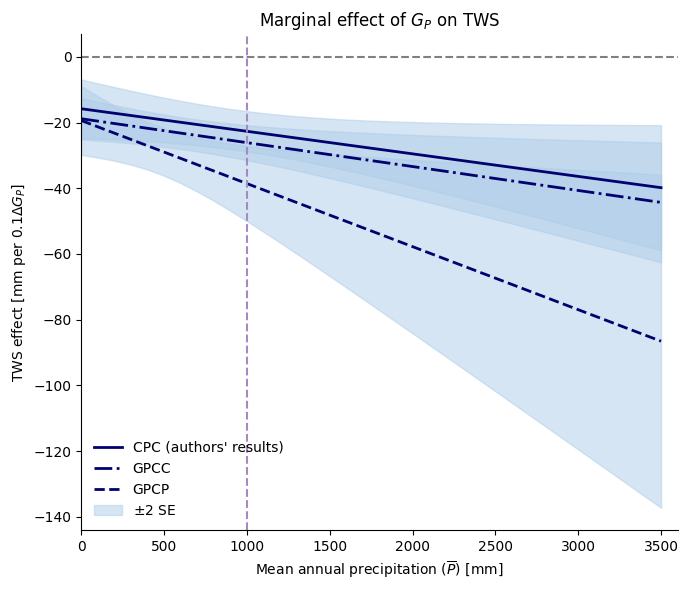

Figure saved: /content/drive/MyDrive/ecohydro_project/Project 2/Stage 1/Benchmark_Reproduction/Marginal_Effect_Curve/Figure_2b_Marginal_Effect_Reproduction.png


In [20]:
# AUTHORS' FIGURE 2b PLOTTING APPROACH


fig, ax = plt.subplots(figsize=(7, 6))

col_p = "#01016f"
col_gp1000 = "#aecde8"

# CPC: solid line
l1, = ax.plot(
    x, y,
    color=col_p,
    linewidth=2,
    linestyle="-",
    label="CPC (authors' results)"
)

s1 = ax.fill_between(
    x, effecthi, effectlo,
    color=col_gp1000,
    alpha=0.5
)

# GPCC: dash-dot line
l2, = ax.plot(
    x, ygpcc,
    color=col_p,
    linewidth=2,
    linestyle="-.",
    label="GPCC"
)

ax.fill_between(
    x, effecthi_gpcc, effectlo_gpcc,
    color=col_gp1000,
    alpha=0.5
)

# GPCP: dashed line
l3, = ax.plot(
    x, ygpcp,
    color=col_p,
    linewidth=2,
    linestyle="--",
    label="GPCP"
)

ax.fill_between(
    x, effecthi_gpcp, effectlo_gpcp,
    color=col_gp1000,
    alpha=0.5
)

# Reference lines
ax.axhline(0, linestyle="--", color="grey")
ax.axvline(1000, linestyle="--", color="#a38bbf")

# Axis labels
ax.set_xlabel(
    r"Mean annual precipitation ($\overline{P}$) [mm]"
)

ax.set_ylabel(
    r"TWS effect [mm per $0.1 \Delta G_P$]"
)

ax.set_title(
    r"Marginal effect of $G_P$ on TWS"
)

ax.set_xlim(0, 3600)

# Legend
legend = ax.legend(
    [l1, l2, l3, s1],
    [
        "CPC (authors' results)",
        "GPCC",
        "GPCP",
        r"$\pm 2$ SE"
    ],
    loc="lower left",
    frameon=False,
    fontsize=10
)

ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()

# Save figure
figure_path = (
    MARGINAL_DIR / "Figure_2b_Marginal_Effect_Reproduction.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)

### Data provenance and reproduction note — Stage 1.3

The marginal-effect curves were calculated using the method implemented in the original `lesk+mankin_main-figs.ipynb` notebook from the Lesk and Mankin (2026) GitHub repository.

- **GPCC:** Marginal effects and uncertainty bands were calculated using the GPCC regression results independently reproduced in Stage 1.2.
- **GPCP:** Marginal effects and uncertainty bands were calculated using the GPCP regression results independently reproduced in Stage 1.2.
- **CPC:** The authors' original `CPC_regression_results.csv` from the GitHub repository was used because the independent CPC regression could not be completed due to the unresolved `basin_id` lookup issue.

Therefore, the CPC curve represents the authors' published regression results and is included as a reference for comparison. It is not an independently reproduced CPC regression result.

The marginal-effect calculation and plotting procedure follow the authors' original implementation, with file paths and data sources adapted for this reproduction workflow.